In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import torch
import torch.nn as nn
import joblib
import shap
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, classification_report,
                             roc_curve, precision_recall_curve)
from scipy.sparse import hstack
from torch.utils.data import DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# ── Căi ──────────────────────────────────────────────────
PREP_PATH  = "/kaggle/input/notebooks/catalinagligor22/02-preprocessing/"   # output notebook 02
TRAIN_PATH = "/kaggle/input/notebooks/catalinagligor22/03-training/"        # output notebook 03
OUTPUT_DIR = "/kaggle/working/"

# ── Încărcare date ────────────────────────────────────────
X_test_img  = np.load(PREP_PATH + 'X_test_img.npy')
y_test_img  = np.load(PREP_PATH + 'y_test_img.npy')
X_val_img   = np.load(PREP_PATH + 'X_val_img.npy')
y_val_img   = np.load(PREP_PATH + 'y_val_img.npy')

df_test     = pd.read_csv(PREP_PATH + 'clinical_test.csv')
df_val      = pd.read_csv(PREP_PATH + 'clinical_val.csv')

preprocessor = joblib.load(PREP_PATH + 'preprocessor.pkl')
tfidf        = joblib.load(PREP_PATH + 'tfidf_vectorizer.pkl')
xgb          = joblib.load(TRAIN_PATH + 'xgboost_model.pkl')
lr_model     = joblib.load(TRAIN_PATH + 'logistic_regression.pkl')

print("✅ Date și modele încărcate!")
print(f"   Test imagini:   {X_test_img.shape}")
print(f"   Test pacienti:  {len(df_test)}")

✅ Date și modele încărcate!
   Test imagini:   (660, 256, 256)
   Test pacienti:  10271


In [3]:
# Redefinim arhitectura U-Net (identică cu notebook 03)
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True))
    def forward(self, x): return self.block(x)

class UNet(nn.Module):
    def __init__(self, features=[64, 128, 256, 512]):
        super().__init__()
        self.encoders = nn.ModuleList()
        self.pools    = nn.ModuleList()
        in_ch = 1
        for f in features:
            self.encoders.append(DoubleConv(in_ch, f))
            self.pools.append(nn.MaxPool2d(2))
            in_ch = f
        self.bottleneck = DoubleConv(features[-1], features[-1]*2)
        self.upconvs  = nn.ModuleList()
        self.decoders = nn.ModuleList()
        for f in reversed(features):
            self.upconvs.append(nn.ConvTranspose2d(f*2, f, 2, stride=2))
            self.decoders.append(DoubleConv(f*2, f))
        self.output = nn.Conv2d(features[0], 1, 1)

    def forward(self, x):
        skips = []
        for enc, pool in zip(self.encoders, self.pools):
            x = enc(x); skips.append(x); x = pool(x)
        x = self.bottleneck(x)
        skips = skips[::-1]
        for up, dec, skip in zip(self.upconvs, self.decoders, skips):
            x = up(x); x = torch.cat([skip, x], dim=1); x = dec(x)
        return torch.sigmoid(self.output(x))

# Încarcă greutățile salvate
unet = UNet().to(device)
unet.load_state_dict(torch.load(TRAIN_PATH + 'unet_best.pth', map_location=device))
unet.eval()
print(" U-Net încărcat!")

 U-Net încărcat!


**Evaluare performantei modelului U-NET**

Se evaluează performanța modelului U-Net pe setul de test utilizând două metrici standard pentru segmentarea imagistică: Dice Score și IoU. 


In [4]:
def dice_score(pred, target, threshold=0.5, smooth=1e-6):
    pred_bin = (pred > threshold).float()
    inter = (pred_bin * target).sum()
    return ((2. * inter + smooth) / (pred_bin.sum() + target.sum() + smooth)).item()

def iou_score(pred, target, threshold=0.5, smooth=1e-6):
    pred_bin = (pred > threshold).float()
    inter = (pred_bin * target).sum()
    union = pred_bin.sum() + target.sum() - inter
    return ((inter + smooth) / (union + smooth)).item()

# Rulează pe test set
test_imgs_t  = torch.tensor(X_test_img, dtype=torch.float32).unsqueeze(1).to(device)
test_masks_t = torch.tensor(y_test_img, dtype=torch.float32).unsqueeze(1)

all_dices, all_ious = [], []

with torch.no_grad():
    batch_size = 16
    for i in range(0, len(test_imgs_t), batch_size):
        batch = test_imgs_t[i:i+batch_size]
        preds = unet(batch).cpu()
        masks = test_masks_t[i:i+batch_size]
        for p, m in zip(preds, masks):
            all_dices.append(dice_score(p, m))
            all_ious.append(iou_score(p, m))

mean_dice = np.mean(all_dices)
mean_iou  = np.mean(all_ious)

print("=" * 40)
print("  EVALUARE U-Net — TEST SET")
print("=" * 40)
print(f"  Dice Score : {mean_dice:.4f}")
print(f"  IoU Score  : {mean_iou:.4f}")
print("=" * 40)

  EVALUARE U-Net — TEST SET
  Dice Score : 0.9651
  IoU Score  : 0.9331


Modelul a obținut :
* Dice Score de 0.9651, care măsoară gradul de suprapunere dintre masca prezisă și masca reală.
* IoU de 0.9331, care exprimă raportul dintre zona comună și uniunea celor două măști.
 
Valorile ridicate ale acestor metrici indică o segmentare foarte precisă și confirmă faptul că modelul generalizează bine pe datele nevăzute.

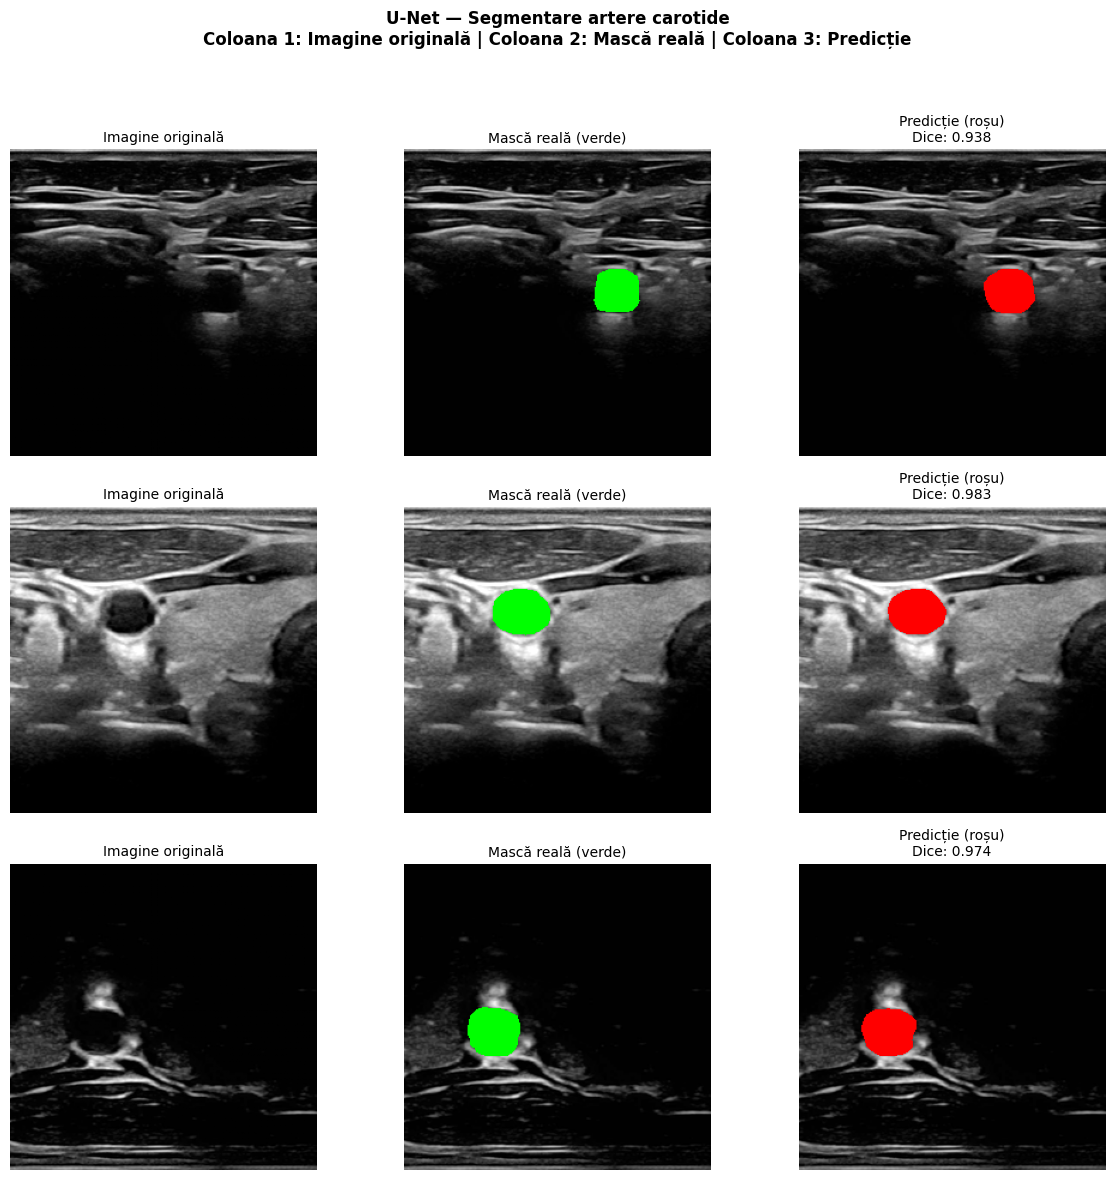

✅ Vizualizare segmentări salvată!


In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 12))
fig.suptitle(
    'U-Net — Segmentare artere carotide\n'
    'Coloana 1: Imagine originală | Coloana 2: Mască reală | Coloana 3: Predicție',
    fontweight='bold',
    fontsize=12
)

indices = [0, 50, 100]

with torch.no_grad():
    for row, i in enumerate(indices):
        img   = test_imgs_t[i:i+1]
        pred  = unet(img).cpu().squeeze().numpy()
        true  = y_test_img[i]
        image = X_test_img[i]

        pred_bin = (pred > 0.5).astype(np.float32)

        # 1. Imagine originală
        axes[row, 0].imshow(image, cmap='gray')
        axes[row, 0].set_title('Imagine originală', fontsize=10)
        axes[row, 0].axis('off')

        # 2. Mască reală - verde
        true_overlay = np.stack([image, image, image], axis=-1)
        true_overlay[true > 0.5] = [0.0, 1.0, 0.0]   # verde = masca reală
        axes[row, 1].imshow(true_overlay)
        axes[row, 1].set_title('Mască reală (verde)', fontsize=10)
        axes[row, 1].axis('off')

        # 3. Predicție - roșu
        pred_overlay = np.stack([image, image, image], axis=-1)
        pred_overlay[pred_bin > 0.5] = [1.0, 0.0, 0.0]   # roșu = predicție
        axes[row, 2].imshow(pred_overlay)
        dice = dice_score(torch.tensor(pred), torch.tensor(true))
        axes[row, 2].set_title(f'Predicție (roșu)\nDice: {dice:.3f}', fontsize=10)
        axes[row, 2].axis('off')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig(OUTPUT_DIR + 'unet_predictions_colored.png', dpi=150)
plt.show()
print("✅ Vizualizare segmentări salvată!")

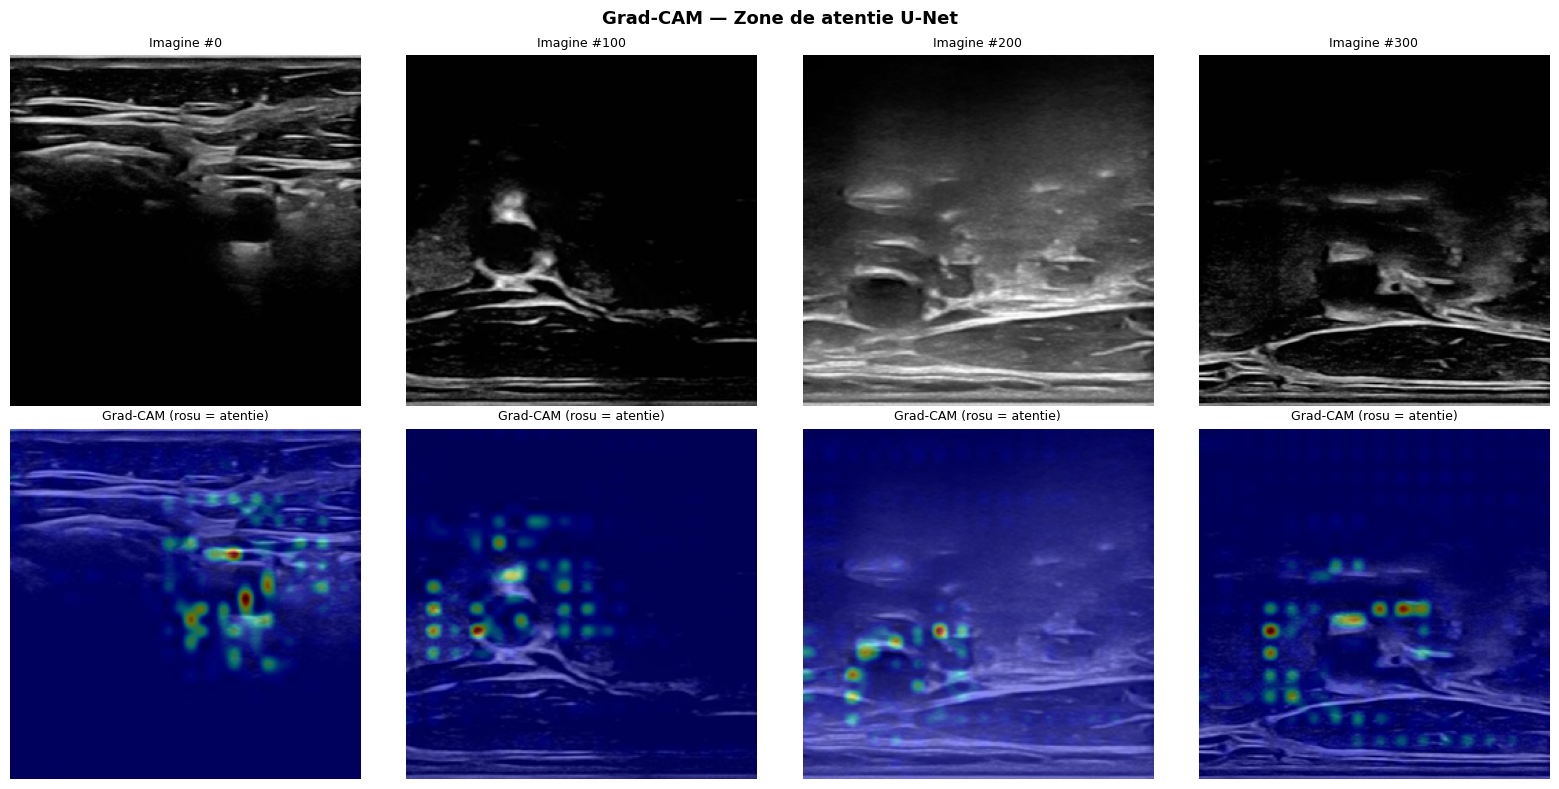

✅ Grad-CAM salvat!


In [8]:
from PIL import Image as PILImage

def get_gradcam(model, image_tensor):
    """Grad-CAM pe ultimul bloc encoder al U-Net."""
    gradients  = []
    activations = []

    # Hook pe ultimul encoder (features[-1] = 512 canale)
    target_layer = model.encoders[-1]

    def forward_hook(module, input, output):
        activations.append(output.detach())

    def backward_hook(module, grad_input, grad_output):
        gradients.append(grad_output[0].detach())

    fh = target_layer.register_forward_hook(forward_hook)
    bh = target_layer.register_backward_hook(backward_hook)

    # Activează gradienți și rulează modelul în train mode temporar
    model.train()  # ← FIX: eval() blochează gradienții pentru hook-uri
    output = model(image_tensor)
    model.zero_grad()
    output.mean().backward()
    model.eval()   # ← revii la eval după

    fh.remove()
    bh.remove()

    grad  = gradients[0].cpu().numpy()[0].mean(axis=0)   # medie pe canale
    activ = activations[0].cpu().numpy()[0].mean(axis=0)
    cam   = np.maximum(grad * activ, 0)
    cam   = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

    # Resize la 256x256
    cam_resized = np.array(PILImage.fromarray(cam).resize((256, 256)))
    return cam_resized

# Vizualizare Grad-CAM pe 4 exemple
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle('Grad-CAM — Zone de atentie U-Net', fontweight='bold', fontsize=13)

for i, idx in enumerate([0, 100, 200, 300]):
    # Imaginea trebuie să aibă requires_grad=True
    img_t = torch.tensor(X_test_img[idx:idx+1],
                         dtype=torch.float32).unsqueeze(0).to(device)
    # Shape: (1, 1, 256, 256)
    img_t = img_t.squeeze(0).requires_grad_(True)

    cam = get_gradcam(unet, img_t.unsqueeze(0))

    axes[0, i].imshow(X_test_img[idx], cmap='gray')
    axes[0, i].set_title(f'Imagine #{idx}', fontsize=9)
    axes[0, i].axis('off')

    axes[1, i].imshow(X_test_img[idx], cmap='gray')
    axes[1, i].imshow(cam, cmap='jet', alpha=0.45)
    axes[1, i].set_title('Grad-CAM (rosu = atentie)', fontsize=9)
    axes[1, i].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'gradcam.png', dpi=150)
plt.show()
print("✅ Grad-CAM salvat!")

Ce se observa? 
* Modelul nu axează pe toata imaginea, focusul fiind doar pe zona de interes
* Atenția apare în apropierea arterei sau a contururilor acestora, ceea ce sugerează că modelul a învățat să folosească indicii utile pentru segmentare.
* Există și pete de atenție în zone care par mai puțin relevante: Grad-CAM nu este perfect ci arată doar contribuția relativă a zonelor din imagine.


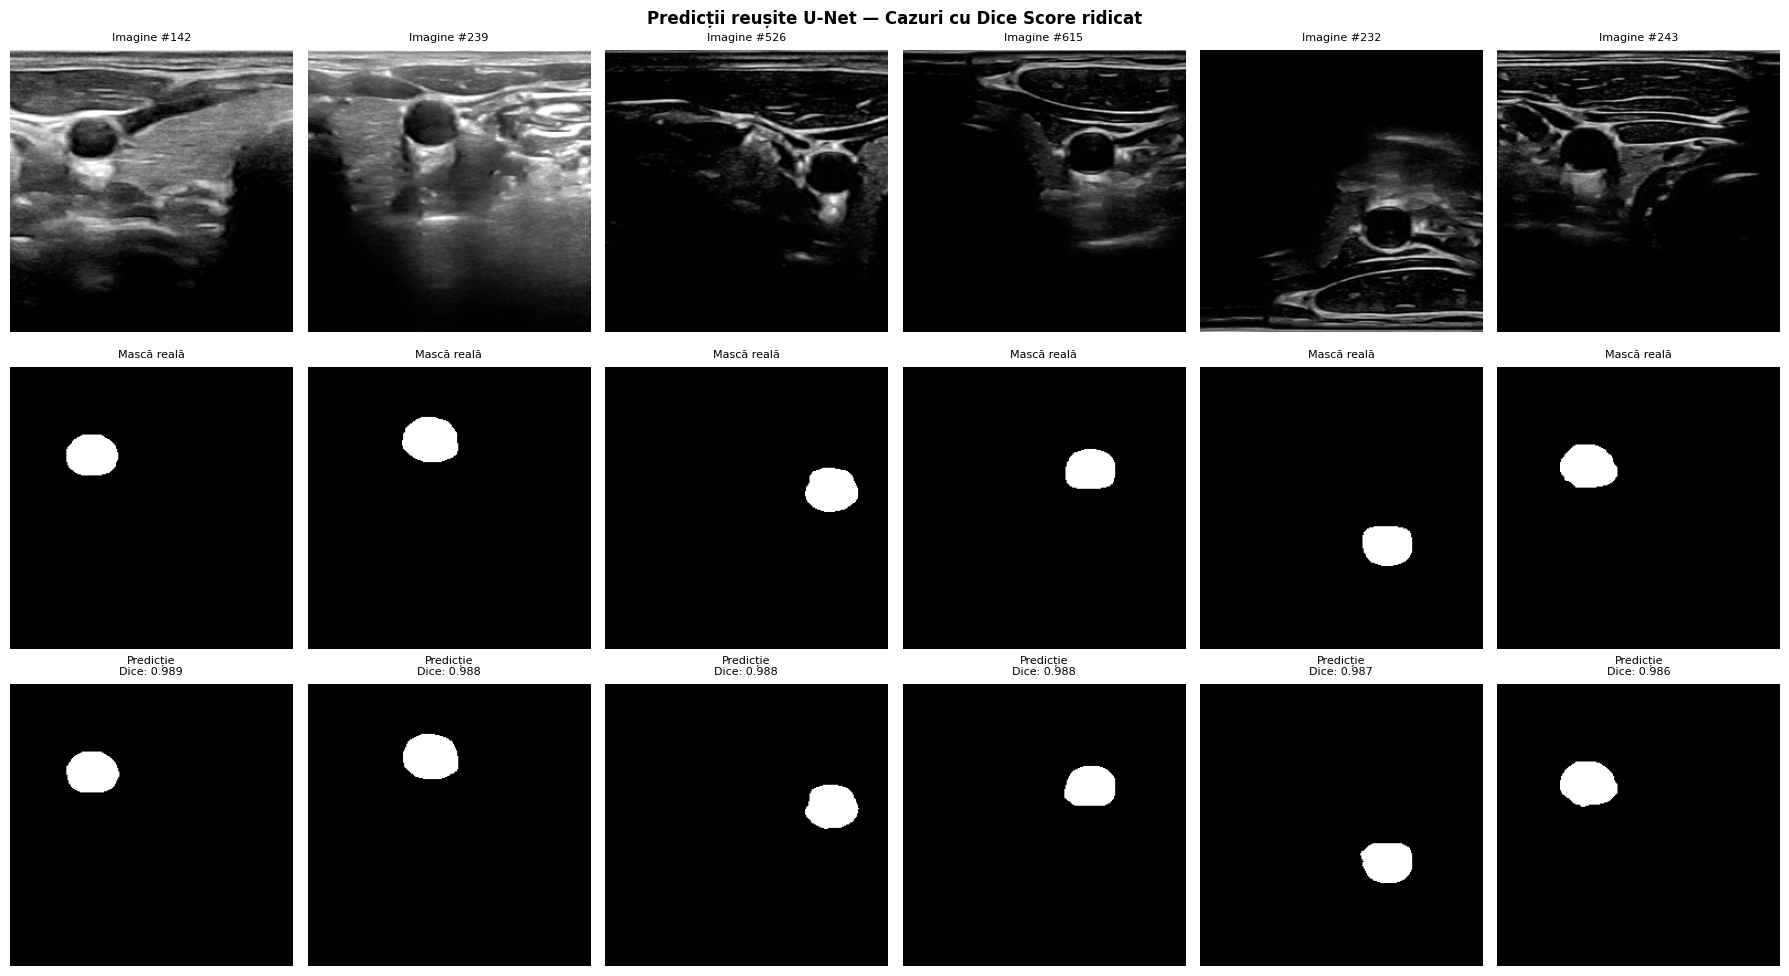

✅ Cele mai bune predicții salvate!


In [29]:
# Cele mai bune 6 predicții (Dice Score maxim)
high_dice_indices = np.argsort(all_dices)[-6:][::-1]

fig, axes = plt.subplots(3, 6, figsize=(18, 10))
fig.suptitle('Predicții reușite U-Net — Cazuri cu Dice Score ridicat',
             fontweight='bold', fontsize=12)

with torch.no_grad():
    for col, idx in enumerate(high_dice_indices):
        img  = test_imgs_t[idx:idx+1]
        pred = unet(img).cpu().squeeze().numpy()
        true = y_test_img[idx]

        # Rând 1: imaginea originală
        axes[0, col].imshow(X_test_img[idx], cmap='gray')
        axes[0, col].set_title(f'Imagine #{idx}', fontsize=8)
        axes[0, col].axis('off')

        # Rând 2: masca reală (ground truth)
        axes[1, col].imshow(true, cmap='gray')
        axes[1, col].set_title('Mască reală', fontsize=8)
        axes[1, col].axis('off')

        # Rând 3: predicția modelului
        axes[2, col].imshow(pred > 0.5, cmap='gray')
        axes[2, col].set_title(f'Predicție\nDice: {all_dices[idx]:.3f}', fontsize=8)
        axes[2, col].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'best_predictions.png', dpi=150)
plt.show()
print("✅ Cele mai bune predicții salvate!")

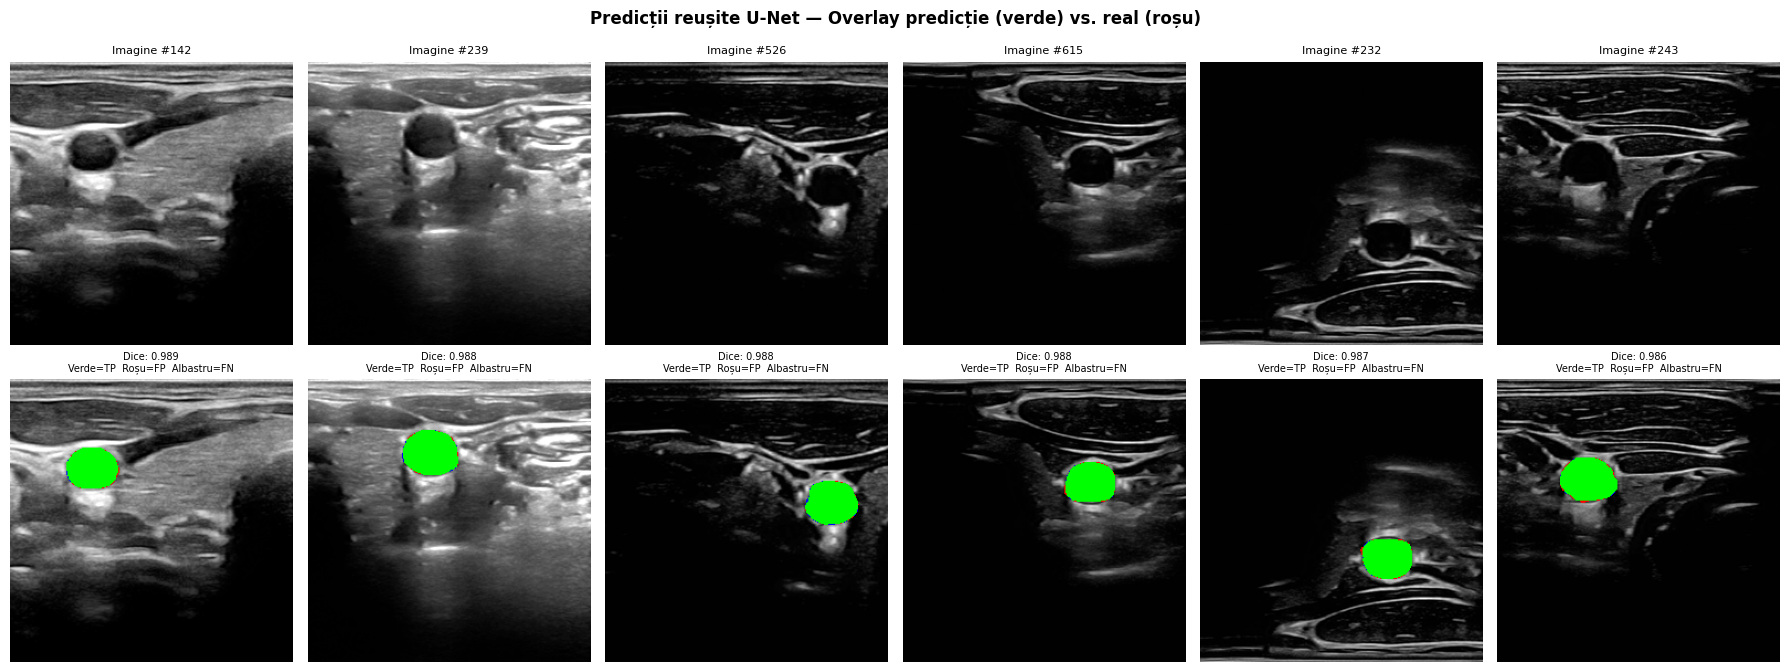

✅ Overlay predicții salvat!


In [30]:
high_dice_indices = np.argsort(all_dices)[-6:][::-1]

fig, axes = plt.subplots(2, 6, figsize=(18, 7))
fig.suptitle('Predicții reușite U-Net — Overlay predicție (verde) vs. real (roșu)',
             fontweight='bold', fontsize=12)

with torch.no_grad():
    for col, idx in enumerate(high_dice_indices):
        img  = test_imgs_t[idx:idx+1]
        pred = (unet(img).cpu().squeeze().numpy() > 0.5).astype(float)
        true = y_test_img[idx]

        # Rând 1: imaginea originală
        axes[0, col].imshow(X_test_img[idx], cmap='gray')
        axes[0, col].set_title(f'Imagine #{idx}', fontsize=8)
        axes[0, col].axis('off')

        # Rând 2: overlay colorat
        # Verde = predicție corectă, Roșu = fals pozitiv, Albastru = fals negativ
        overlay = np.stack([X_test_img[idx]]*3, axis=-1)

        tp = (pred == 1) & (true == 1)   # predicție corectă → verde
        fp = (pred == 1) & (true == 0)   # fals pozitiv → roșu
        fn = (pred == 0) & (true == 1)   # fals negativ → albastru

        overlay[tp, 0] = 0.0; overlay[tp, 1] = 1.0; overlay[tp, 2] = 0.0
        overlay[fp, 0] = 1.0; overlay[fp, 1] = 0.0; overlay[fp, 2] = 0.0
        overlay[fn, 0] = 0.0; overlay[fn, 1] = 0.0; overlay[fn, 2] = 1.0

        axes[1, col].imshow(overlay)
        axes[1, col].set_title(f'Dice: {all_dices[idx]:.3f}\n'
                                f'Verde=TP  Roșu=FP  Albastru=FN',
                                fontsize=7)
        axes[1, col].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'best_predictions_overlay.png', dpi=150)
plt.show()
print("✅ Overlay predicții salvat!")

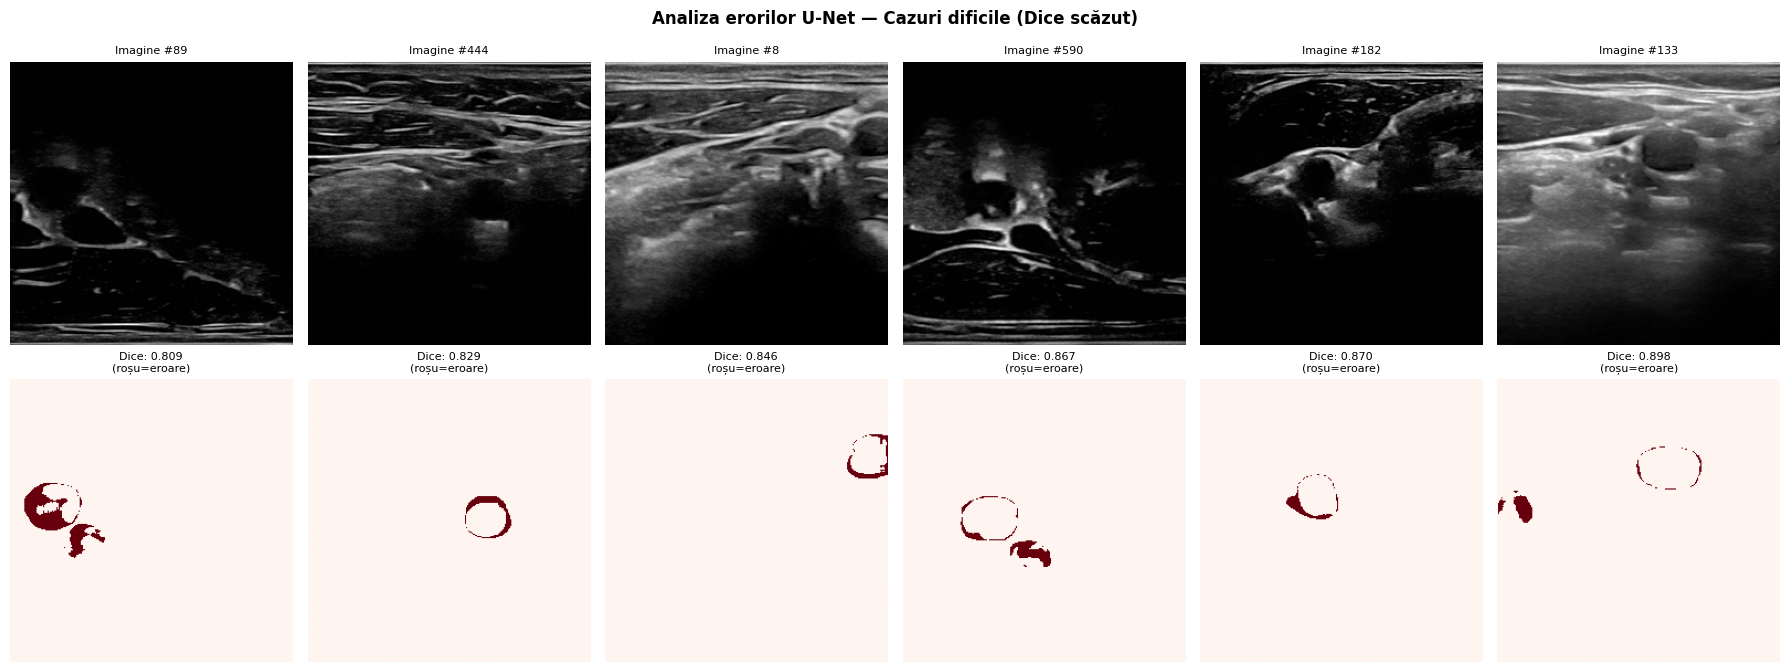

Analiza erorilor salvată!


In [10]:
# Găsește imaginile cu Dice Score mic (greșeli)
low_dice_indices = np.argsort(all_dices)[:6]  # cele mai slabe 6

fig, axes = plt.subplots(2, 6, figsize=(18, 7))
fig.suptitle('Analiza erorilor U-Net — Cazuri dificile (Dice scăzut)',
             fontweight='bold', fontsize=12)

with torch.no_grad():
    for col, idx in enumerate(low_dice_indices):
        img  = test_imgs_t[idx:idx+1]
        pred = unet(img).cpu().squeeze().numpy()
        true = y_test_img[idx]

        axes[0, col].imshow(X_test_img[idx], cmap='gray')
        axes[0, col].set_title(f'Imagine #{idx}', fontsize=8)
        axes[0, col].axis('off')

        # Eroarea = diferența dintre predicție și ground truth
        error_map = np.abs((pred > 0.5).astype(float) - true)
        axes[1, col].imshow(error_map, cmap='Reds', vmin=0, vmax=1)
        axes[1, col].set_title(f'Dice: {all_dices[idx]:.3f}\n(roșu=eroare)',
                                fontsize=8)
        axes[1, col].axis('off')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'error_analysis.png', dpi=150)
plt.show()
print("Analiza erorilor salvată!")

In [21]:
# Pregătire features test
numeric_features   = ['age_years', 'ap_hi', 'ap_lo', 'bmi', 'pulse_pressure']
categoric_features = ['gender', 'cholesterol', 'gluc', 'smoke', 'alco', 'active']

X_test_tab   = preprocessor.transform(df_test[numeric_features + categoric_features])
X_test_tfidf = tfidf.transform(df_test['risk_text'])
X_test_clin  = hstack([X_test_tab, X_test_tfidf])
y_test_clin  = df_test['cardio'].values

# Predicții
xgb_pred  = xgb.predict(X_test_clin)
xgb_proba = xgb.predict_proba(X_test_clin)[:, 1]
lr_pred   = lr_model.predict(X_test_clin)
lr_proba  = lr_model.predict_proba(X_test_clin)[:, 1]

# Metrici
results = {
    'XGBoost': {
        'Accuracy':  accuracy_score(y_test_clin, xgb_pred),
        'F1-Score':  f1_score(y_test_clin, xgb_pred),
        'AUC-ROC':   roc_auc_score(y_test_clin, xgb_proba)
    },
    'Logistic Regression': {
        'Accuracy':  accuracy_score(y_test_clin, lr_pred),
        'F1-Score':  f1_score(y_test_clin, lr_pred),
        'AUC-ROC':   roc_auc_score(y_test_clin, lr_proba)
    }
}

df_results = pd.DataFrame(results).T
print("=" * 55)
print("  TABEL COMPARATIV MODELE CLINICE — TEST SET")
print("=" * 55)
print(df_results.round(4).to_string())
print("=" * 55)
print(f"\n✅ Model ales: XGBoost (AUC: {results['XGBoost']['AUC-ROC']:.4f})")

  TABEL COMPARATIV MODELE CLINICE — TEST SET
                     Accuracy  F1-Score  AUC-ROC
XGBoost                0.7382    0.7226    0.806
Logistic Regression    0.7271    0.7087    0.796

✅ Model ales: XGBoost (AUC: 0.8060)


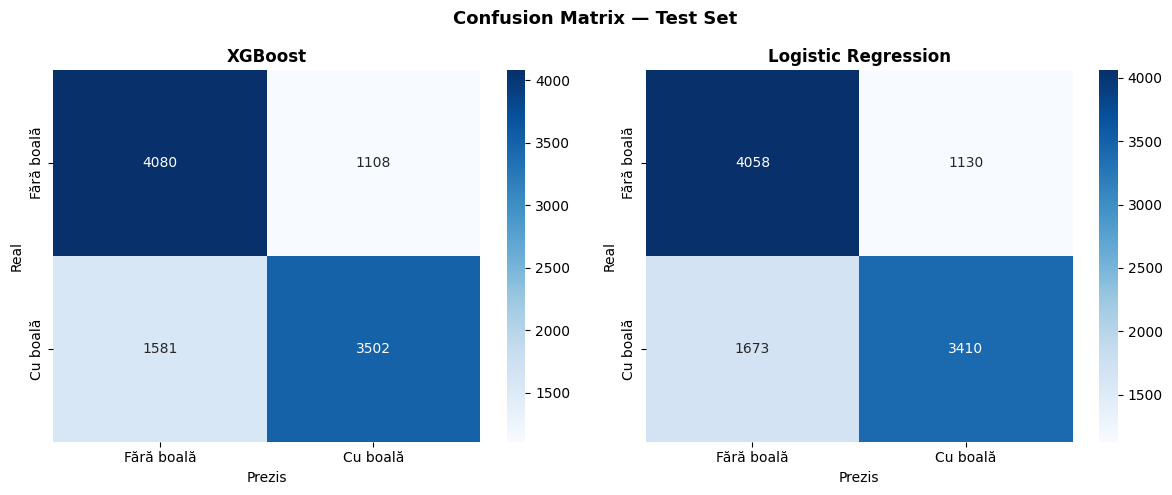

✅ Confusion matrices salvate!


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle('Confusion Matrix — Test Set', fontweight='bold', fontsize=13)

for ax, (name, pred) in zip(axes, [('XGBoost', xgb_pred),
                                     ('Logistic Regression', lr_pred)]):
    cm = confusion_matrix(y_test_clin, pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Fără boală', 'Cu boală'],
                yticklabels=['Fără boală', 'Cu boală'])
    ax.set_title(name, fontweight='bold')
    ax.set_ylabel('Real')
    ax.set_xlabel('Prezis')

plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'confusion_matrices.png', dpi=150)
plt.show()
print("✅ Confusion matrices salvate!")

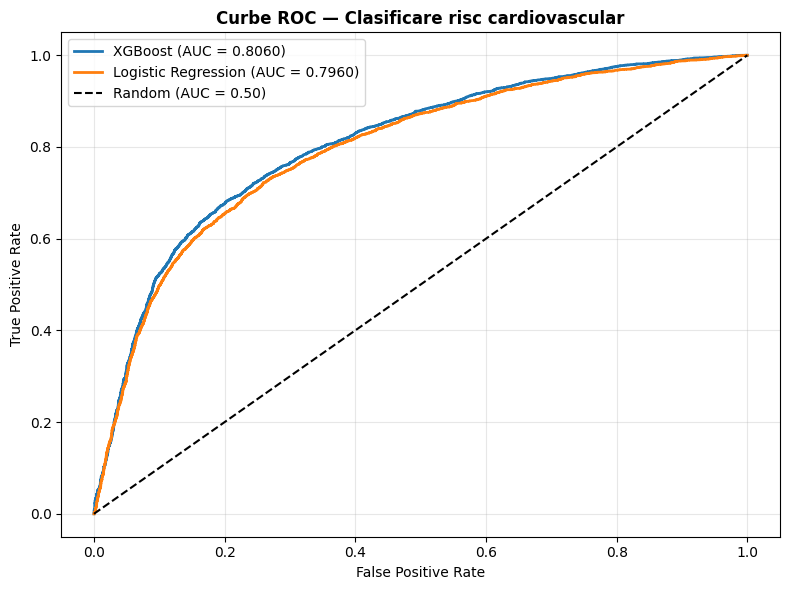

✅ Curbe ROC salvate!


In [23]:
fig, ax = plt.subplots(figsize=(8, 6))

for name, proba in [('XGBoost', xgb_proba), ('Logistic Regression', lr_proba)]:
    fpr, tpr, _ = roc_curve(y_test_clin, proba)
    auc = roc_auc_score(y_test_clin, proba)
    ax.plot(fpr, tpr, linewidth=2, label=f'{name} (AUC = {auc:.4f})')

ax.plot([0,1], [0,1], 'k--', label='Random (AUC = 0.50)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('Curbe ROC — Clasificare risc cardiovascular', fontweight='bold')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR + 'roc_curves.png', dpi=150)
plt.show()
print("✅ Curbe ROC salvate!")

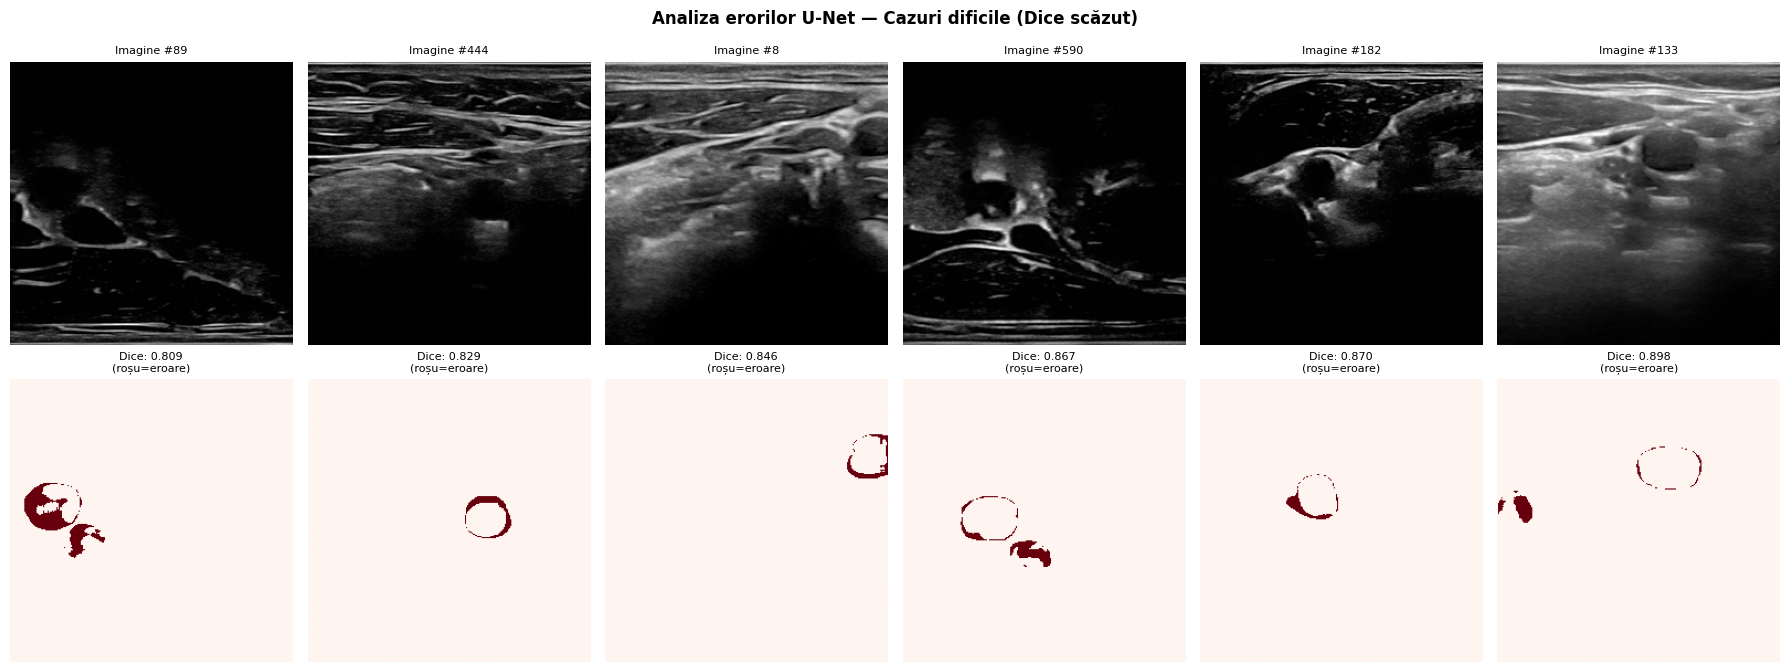

Analiza erorilor salvată!


In [28]:
print("""
╔══════════════════════════════════════════════════════╗
║           REZUMAT EVALUARE FINALĂ                    ║
╠══════════════════════════════════════════════════════╣
║  COMPUTER VISION — U-Net                             ║
║  • Dice Score  : {:.4f}                              ║
║  • IoU Score   : {:.4f}                              ║
╠══════════════════════════════════════════════════════╣
║  NLP + ML CLASIC                                     ║
║  • XGBoost     — AUC: {:.4f}  F1: {:.4f}             ║
║  • Log. Regr.  — AUC: {:.4f}  F1: {:.4f}             ║
╠══════════════════════════════════════════════════════╣
║  MODEL FINAL ALES: XGBoost                           ║
╚══════════════════════════════════════════════════════╝
""".format(
    mean_dice, mean_iou,
    results['XGBoost']['AUC-ROC'],        results['XGBoost']['F1-Score'],
    results['Logistic Regression']['AUC-ROC'], results['Logistic Regression']['F1-Score']
))

# Salvare tabel final
df_results.to_csv(OUTPUT_DIR + 'evaluation_results.csv')
print("Toate graficele și rezultatele salvate în Output!")


╔══════════════════════════════════════════════════════╗
║           REZUMAT EVALUARE FINALĂ                    ║
╠══════════════════════════════════════════════════════╣
║  COMPUTER VISION — U-Net                             ║
║  • Dice Score  : 0.9651                              ║
║  • IoU Score   : 0.9331                              ║
╠══════════════════════════════════════════════════════╣
║  NLP + ML CLASIC                                     ║
║  • XGBoost     — AUC: 0.8060  F1: 0.7226             ║
║  • Log. Regr.  — AUC: 0.7960  F1: 0.7087             ║
╠══════════════════════════════════════════════════════╣
║  MODEL FINAL ALES: XGBoost                           ║
╚══════════════════════════════════════════════════════╝

Toate graficele și rezultatele salvate în Output!
